# 6. Query-based detector: RT-DETR
## How it works
RT-DETR is a **transformer**. It has 300 **queries**. A query is like a searcher. Every query looks at the image with **attention** and finds one object or says "nothing".

**Bipartite matching.** In training every true object gets exactly one query. So the model learns to give one box per object. We do not need NMS to remove duplicate boxes.

Transformers usually learn slower than CNNs and they are weaker on small objects.

## Experiments
Same budget as the other models (3 epochs).
* **baseline**: learning rate 0.0001
* **lr x2**: learning rate 0.0002

## Imports and paths
Libraries and the folders for the data, the training files and the figures.

In [1]:
import os
import io
import json
import time
import random
import contextlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageDraw
import torch

In [2]:
if os.path.exists("/kaggle/input"):
    import glob
    DATA = os.path.dirname(glob.glob("/kaggle/input/**/test_images.csv", recursive=True)[0])
    WORK = "/kaggle/working/work"
elif os.name == "nt":
    DATA = "D:/hw2/data"
    WORK = "D:/hw2/work"
else:
    DATA = "/content/data"
    WORK = "/content/work"

# Figures for the report go to the images folder of the repository.
IMAGES = "../images"
RESULTS_FILE = "experiments.csv"
os.makedirs(WORK, exist_ok=True)
os.makedirs(IMAGES, exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 36
print("data:", DATA)
print("device:", DEVICE)

data: D:/hw2/data
device: cuda


## Functions
This notebook uses the functions below. Every function does one simple job.

`free_memory` cleans the memory of the GPU and the computer after a model is done.

In [3]:
def free_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

`train_ultralytics` trains YOLO or RT-DETR with Ultralytics. It returns the path of the best weights, the file with the per-epoch scores and the minutes.

In [4]:
def train_ultralytics(weights, data_yaml, size, epochs, batch, name, val_each_epoch, **params):
    """Train YOLO or RT-DETR. Returns the path of the best weights, the training curve file and minutes."""
    from ultralytics import YOLO, RTDETR

    if "rtdetr" in weights:
        model = RTDETR(weights)
    else:
        model = YOLO(weights)
    # Folder names: only letters and numbers.
    name = "".join(c if c.isalnum() else "_" for c in name)
    # On Windows every data worker takes about 1 GB of RAM.
    workers = 1 if os.name == "nt" else 4
    start = time.time()
    model.train(data=data_yaml, imgsz=size, epochs=epochs, batch=batch, seed=SEED, workers=workers,
                project=f"{WORK}/runs", name=name, exist_ok=True, plots=False, verbose=False,
                val=val_each_epoch, **params)
    minutes = (time.time() - start) / 60
    best = str(model.trainer.best)
    curve = f"{model.trainer.save_dir}/results.csv"
    del model
    free_memory()
    return best, curve, minutes

`ultralytics_predictor` turns Ultralytics weights into a function: image -> boxes, scores, classes.

In [5]:
def ultralytics_predictor(weights, size):
    """Returns a function: image -> boxes, scores, classes (0..7)."""
    from ultralytics import YOLO, RTDETR

    if "rtdetr" in str(weights):
        model = RTDETR(weights)
    else:
        model = YOLO(weights)

    def predict(image):
        # Ultralytics wants BGR colour order.
        bgr = np.ascontiguousarray(image[:, :, ::-1])
        result = model.predict(bgr, imgsz=size, conf=0.001, max_det=500, verbose=False)[0].boxes
        return result.xyxy.cpu().numpy(), result.conf.cpu().numpy(), result.cls.cpu().numpy().astype(int)

    return predict

`predict_frame` predicts one frame and keeps the 500 best boxes.

In [6]:
def predict_frame(predict, path):
    """Predict one frame. Keep the 500 boxes with the best scores (Kaggle uses at most 500)."""
    image = np.array(Image.open(path).convert("RGB"))
    boxes, scores, classes = predict(image)
    order = np.argsort(-scores)[:500]
    return boxes[order], scores[order], classes[order]

`evaluate` scores a model on the validation frames with the COCO metric (pycocotools). Ignored regions have `iscrowd = 1`, so boxes there are not errors. It also measures the speed (ms per image).

In [7]:
def evaluate(predict, val_frames):
    """
    COCO score on the validation frames.
    Ignored regions are marked iscrowd=1, so boxes inside them are not counted as errors.
    """
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    detections = []
    predictions = []
    start = time.time()
    for row in val_frames.itertuples():
        boxes, scores, classes = predict_frame(predict, row.path)
        predictions.append((boxes, scores, classes))
        for box, score, cls in zip(boxes, scores, classes):
            x1, y1, x2, y2 = [float(v) for v in box]
            detections.append({"image_id": int(row.image_id), "category_id": int(cls) + 1,
                               "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(score)})
    ms_per_image = (time.time() - start) / len(val_frames) * 1000

    with open(f"{DATA}/val/annotations_coco.json") as f:
        ground_truth = json.load(f)
    for a in ground_truth["annotations"]:
        a.setdefault("iscrowd", 0)
        a.setdefault("area", a["bbox"][2] * a["bbox"][3])

    result = {"mAP": 0.0, "AP50": 0.0, "AP_small": 0.0, "AP_medium": 0.0, "AP_large": 0.0}
    if len(detections) > 0:
        # pycocotools prints a lot of text, we hide it.
        with contextlib.redirect_stdout(io.StringIO()):
            gt = COCO()
            gt.dataset = ground_truth
            gt.createIndex()
            E = COCOeval(gt, gt.loadRes(detections), "bbox")
            E.params.imgIds = list(val_frames["image_id"])
            # Up to 500 boxes per frame (scenes are dense).
            E.params.maxDets = [1, 100, 500]
            E.evaluate()
            E.accumulate()
            E.summarize()
        result = {"mAP": E.stats[0], "AP50": E.stats[1], "AP_small": E.stats[3],
                  "AP_medium": E.stats[4], "AP_large": E.stats[5]}
    for key in result:
        result[key] = round(float(result[key]), 4)
    result["ms/img"] = round(ms_per_image, 1)
    return result, predictions

`save_result` adds one line to `experiments.csv`. All notebooks write to this file. We use it in the report.

In [8]:
def save_result(notebook, model, experiment, metrics, minutes):
    """Add one line to experiments.csv. All notebooks write to the same file."""
    row = {"notebook": notebook, "model": model, "experiment": experiment}
    row.update(metrics)
    row["train_min"] = round(minutes, 1)
    if os.path.exists(RESULTS_FILE):
        table = pd.read_csv(RESULTS_FILE, dtype={"notebook": str})
        table = pd.concat([table, pd.DataFrame([row])], ignore_index=True)
    else:
        table = pd.DataFrame([row])
    table.to_csv(RESULTS_FILE, index=False)

## Settings
All models in notebooks 03-06 use the same settings. So we can compare them in a fair way.

The settings are small. One experiment takes only a few minutes.

In [9]:
SIZE = 640
EPOCHS = 3
TRAIN_FOLDER = f"{WORK}/fast/train"
DATA_YAML = f"{WORK}/fast/data.yaml"
val_frames = pd.read_csv(f"{WORK}/val_frames.csv")

print("training images:", len(os.listdir(f"{TRAIN_FOLDER}/images")))
print("validation frames:", len(val_frames))

training images: 271
validation frames: 146


## Train and score
We save the score after every epoch for both runs. Then we can draw the training curves.

In [10]:
import shutil

experiments = {
    "baseline": {"lr0": 0.0001, "optimizer": "AdamW", "warmup_bias_lr": 0.0},
    "lr x2": {"lr0": 0.0002, "optimizer": "AdamW", "warmup_bias_lr": 0.0},
}

results = []
for name in experiments:
    print("=====", name)
    best, curve, minutes = train_ultralytics("rtdetr-l.pt", DATA_YAML, SIZE, EPOCHS, batch=4,
                                             name=f"rtdetr {name}", val_each_epoch=True, **experiments[name])
    shutil.copy(curve, f"curve_rtdetr_{name.replace(' ', '_')}.csv")
    metrics, _ = evaluate(ultralytics_predictor(best, SIZE), val_frames)
    save_result("06", "RT-DETR-L", name, metrics, minutes)
    results.append({"experiment": name, **metrics, "train_min": round(minutes, 1)})
    free_memory()

pd.DataFrame(results)

===== baseline
New https://pypi.org/project/ultralytics/8.4.214 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.205  Python-3.12.5 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 Ti with Max-Q Design, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:/hw2/work/fast/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=

C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/3      5.08G      2.234      1.096      1.116        169        640: 100% ━━━━━━━━━━━━ 68/68 1.0it/s 1:070.9sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.2it/s 16.1s0.5s
                   all        146       5902      0.373      0.112     0.0498     0.0335

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        2/3      5.37G      2.043     0.7827      1.123        161        640: 100% ━━━━━━━━━━━━ 68/68 1.1it/s 1:040.9sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.1it/s 9.0s0.5s
                   all        146       5902      0.322      0.177     0.0679     0.0436

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (4 outputs left out)

        2/3      5.38G      1.858     0.5569     0.8574        161        640: 100% ━━━━━━━━━━━━ 68/68 1.1it/s 1:030.8sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.2it/s 8.7s0.5s
                   all        146       5902      0.359      0.246     0.0935     0.0555

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


C:\Users\HP\AppData\Roaming\Python\Python312\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        3/3      5.39G       1.64     0.4982     0.4694         87        640: 100% ━━━━━━━━━━━━ 68/68 1.1it/s 1:030.9sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.2it/s 8.7s0.5s
                   all        146       5902        0.2      0.284      0.102     0.0583

3 epochs completed in 0.066 hours.
Optimizer stripped from D:\hw2\work\runs\rtdetr_lr_x2\weights\last.pt, 66.2MB
Optimizer stripped from D:\hw2\work\runs\rtdetr_lr_x2\weights\best.pt, 66.2MB

Validating D:\hw2\work\runs\rtdetr_lr_x2\weights\best.pt...
Ultralytics 8.4.205  Python-3.12.5 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1660 Ti with Max-Q Design, 6144MiB)
rt-detr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 2.5it/s 7.7s0.4s
                   all        146       5902      0.202      0.282   

,experiment,mAP,AP50,AP_small,AP_medium,AP_large,ms/img,train_min
0,baseline,0.0560,0.0917,0.0098,0.0556,0.1207,160.8,4.4
1,lr x2,0.0739,0.1281,0.0210,0.0771,0.1367,157.0,4.2


## Training curves: RT-DETR vs YOLO
We draw the validation mAP after every epoch. YOLO (a CNN) comes from notebook 05.

These per-epoch numbers come from Ultralytics. It does not know the ignored regions, so the numbers are lower than our scores. We use them only to see how fast each model learns.

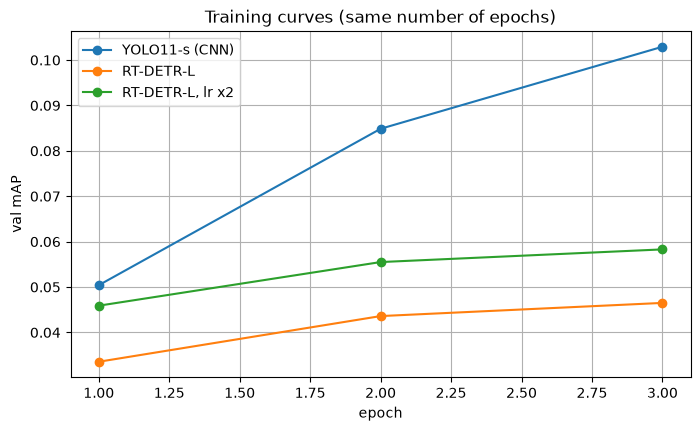

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
runs = {"YOLO11-s (CNN)": "curve_yolo.csv", "RT-DETR-L": "curve_rtdetr_baseline.csv", "RT-DETR-L, lr x2": "curve_rtdetr_lr_x2.csv"}
for label in runs:
    curve = pd.read_csv(runs[label])
    curve.columns = curve.columns.str.strip()
    ax.plot(curve["epoch"], curve["metrics/mAP50-95(B)"], marker="o", label=label)
ax.set_xlabel("epoch")
ax.set_ylabel("val mAP")
ax.set_title("Training curves (same number of epochs)")
ax.legend()
ax.grid(True)
plt.savefig(f"{IMAGES}/06_training_curves.png", dpi=110)
plt.show()

## Conclusions

| experiment | mAP | AP50 | AP_small | AP_medium | AP_large | ms/img | train_min |
|---|---|---|---|---|---|---|---|
| RT-DETR-L, lr 0.0001 | 0.0560 | 0.0917 | 0.0098 | 0.0556 | 0.1207 | 160.8 | 4.4 |
| RT-DETR-L, lr 0.0002 | **0.0739** | **0.1281** | **0.0210** | **0.0771** | **0.1367** | **157.0** | 4.2 |
| *YOLO11-s baseline (notebook 05)* | *0.0896* | | *0.0277* | *0.0796* | *0.2216* | *171.6* | |

**A bug we found: the warm-up**
* The first runs gave **mAP = 0** after every epoch and for both learning rates.
* The reason: in the warm-up Ultralytics uses a learning rate of **0.1 for the bias**. This is fine for YOLO with SGD. For a transformer with AdamW (lr 0.0001) it is 1000 times too big, and it broke the COCO weights.
* With `warmup_bias_lr = 0` RT-DETR learns: mAP 0.056 and 0.074.

**Learning rate**
* lr 0.0002 is better than lr 0.0001 in every metric. AP_small is two times higher (0.021 vs 0.010). With only 3 epochs a bigger step helps the model learn faster.

**Training curves (same budget: 3 epochs)**
* YOLO grows fast: 0.05 → 0.085 → 0.10.
* RT-DETR grows slowly: 0.033 → 0.044 → 0.047 (lr 0.0001) and 0.046 → 0.056 → 0.058 (lr 0.0002).
* **RT-DETR did not converge in 3 epochs:** the curve still goes up. One epoch also takes longer than for YOLO (about 4.3 min of training in total).

**How bipartite matching removes NMS**
* In training every true object gets **exactly one** query (Hungarian matching by class score and box overlap). All other queries must say "no object".
* So the model learns to give **one box per object**. There are no duplicate boxes and we do not need NMS.

**How this changes training**
* At the start the matching is almost random: a query gets a different object in every step. So the model learns slowly, and transformers need more epochs than CNNs. Our curves show this.

**Small objects and dense scenes**
* RT-DETR is weaker than YOLO on small objects (AP_small 0.021 vs 0.028) and on large objects (0.137 vs 0.222).
* Attention works on small feature maps (one point every 8-32 px). An object of 10-20 px is only one point there.
* RT-DETR has **300 queries**. Our frames have up to 180 objects, so in dense frames most queries are busy.